# 加载图片，使用 UnstructuredImageLoader 加载图片并转为 LangChain 的 Document 对象
## 需要安装unstructured pdfminer.six pillow： pip install unstructured pdfminer.six pillow
### 注意：pdfminer.six才是新版本，pdfminer是老版本
## 需要安装pi_heif： pip install pi_heif
## 安装 Python 库 unstructured-inference: pip install unstructured-inference
## 安装pdf2image: pip install pdf2image
## 安装unstructured_pytesseract: pip install unstructured-pytesseract pillow
## 操作系统需要安装tesseract 3.5以上版本，这里我们安装5.0
### 下载地址：https://digi.bib.uni-mannheim.de/tesseract/tesseract-ocr-w64-setup-v5.0.0.20190526.exe



In [5]:
import pprint

from langchain_community.document_loaders import UnstructuredImageLoader


loader = UnstructuredImageLoader(
    file_path="../asset/load/ocrtest.png",
    strategy="hi_res",
    mode="elements"
)

docs = loader.load()
print(len(docs))
pprint.pprint(docs)


No languages specified, defaulting to English.


5
[Document(metadata={'source': '../asset/load/ocrtest.png', 'coordinates': {'points': ((np.float64(0.0), np.float64(6.0)), (np.float64(0.0), np.float64(65.0)), (np.float64(100.0), np.float64(65.0)), (np.float64(100.0), np.float64(6.0))), 'system': 'PixelSpace', 'layout_width': 125, 'layout_height': 123}, 'last_modified': '2026-11-06T16:42:25', 'filetype': 'PNG', 'languages': ['eng'], 'page_number': 1, 'file_directory': '../asset/load', 'filename': 'ocrtest.png', 'category': 'UncategorizedText', 'element_id': '362eed794a8202e7857c47e72f76e291'}, page_content='PRATER iS — BEA'),
 Document(metadata={'source': '../asset/load/ocrtest.png', 'detection_class_prob': 0.3564489781856537, 'coordinates': {'points': ((np.float64(3.9933571815490723), np.float64(10.944158554077148)), (np.float64(3.9933571815490723), np.float64(29.878000259399414)), (np.float64(101.61540985107422), np.float64(29.878000259399414)), (np.float64(101.61540985107422), np.float64(10.944158554077148))), 'system': 'PixelSpac

## mode="paged"

In [8]:
import pprint

from langchain_community.document_loaders import UnstructuredImageLoader


loader = UnstructuredImageLoader(
    file_path="../asset/load/ocrdemo.png",
    strategy="hi_res",
    mode="paged",
)

docs = loader.load()
print(len(docs))
pprint.pprint(docs)


No languages specified, defaulting to English.
`mode='paged'` is deprecated in favor of the 'by_page' chunking strategy. Learn more about chunking here: https://docs.unstructured.io/open-source/core-functionality/chunking


1
[Document(metadata={'source': '../asset/load/ocrdemo.png', 'detection_class_prob': 0.9434101581573486, 'coordinates': {'points': ((np.float64(7.649221420288086), np.float64(142.45343017578125)), (np.float64(7.649221420288086), np.float64(267.67218017578125)), (np.float64(861.2705688476562), np.float64(267.67218017578125)), (np.float64(861.2705688476562), np.float64(142.45343017578125))), 'system': 'PixelSpace', 'layout_width': 884, 'layout_height': 292}, 'last_modified': '2026-11-06T16:48:37', 'filetype': 'PNG', 'languages': ['eng'], 'page_number': 1, 'file_directory': '../asset/load', 'filename': 'ocrdemo.png'}, page_content='Washington — President Trump moved Friday to install longtime aide Stephen Miller as his White House chief of staff, replacing Susie Wiles in the most significant shakeup of his team since Republicans’ losses in the midterm elections.\n\n“| wanted to make a change,” the president told reporters shortly after announcing his decision on Truth Social. "I think Sus


## 注意，默认情况下tesseract不能识别中文，如果有需要，我们可以下载中文训练数据，放到他的安装文件夹的tessdata文件夹里面
### 中文语言包的下载地址： https://github.com/tesseract-ocr/tessdata
### 下载：
#### • 简体中文：chi_sim.traineddata
#### • 繁体中文：chi_tra.traineddata
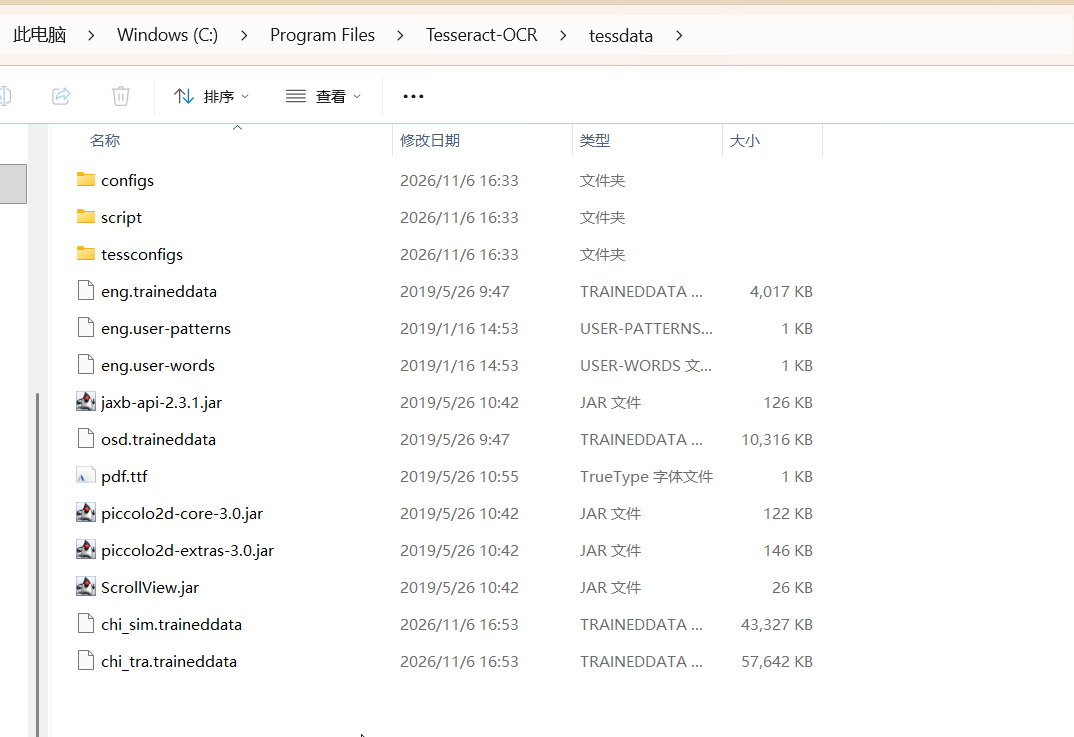
## 如果需要UnstructuredImageLoader能够识别中文，需要在创建这个类的对象的时候把languages设置为中文
```
loader = UnstructuredImageLoader(
    file_path="../asset/load/ocrdemo2.png",
    strategy="hi_res",
    mode="single",
    languages=["chi_sim","chi_tra"] # 把语言设置为简体中文
)
```

In [9]:
import pprint

from langchain_community.document_loaders import UnstructuredImageLoader


loader = UnstructuredImageLoader(
    file_path="../asset/load/ocrdemo2.png",
    strategy="hi_res",
    mode="single",
    languages=["chi_sim","chi_tra"]
)

docs = loader.load()
print(len(docs))
pprint.pprint(docs)
print("================================")
content = docs[0].page_content
print(content.replace(" ","")) # 去除空格


1
[Document(metadata={'source': '../asset/load/ocrdemo2.png'}, page_content='2024 年 9 月 27 日 , 大 碑 娱 乐 发 出 一 份 公 告 , 张 小 斐 、 许 君 聪 等 8 位 同 甘 共 苦 多 年 的 搭 档 到 期 , 不 再 续 签 。 公 司 随 之 宣 布 不 再 开 展 艺 人 经 纪 业 务 , 贾 玲 也 卸 下 了 艺 人 老 板 的 头\n\n合 约 衔 。')]
2024年9月27日,大碑娱乐发出一份公告,张小斐、许君聪等8位同甘共苦多年的搭档到期,不再续签。公司随之宣布不再开展艺人经纪业务,贾玲也卸下了艺人老板的头

合约衔。


## strategy="ocr_only"
### 效果挺好的。

In [11]:
import pprint

from langchain_community.document_loaders import UnstructuredImageLoader


loader = UnstructuredImageLoader(
    # file_path="../asset/load/ocrdemo2.png", # 很好
    file_path="../asset/load/ocrtest.png", # 不太好
    strategy="ocr_only",
    mode="single",
    languages=["chi_sim","chi_tra"]
)

docs = loader.load()
print(len(docs))
pprint.pprint(docs)
print("================================")
content = docs[0].page_content
print(content.replace(" ","")) # 去除空格


1
[Document(metadata={'source': '../asset/load/ocrtest.png'}, page_content='床 前 明 月 光 酥 了 一 碍 汤 举 头 望 明 月 低 头 攘 裤 裆')]
床前明月光酥了一碍汤举头望明月低头攘裤裆
